# Caso práctico · Servicio técnico de equipos celulares
### ODC «Del dato a la toma de decisiones: guía interactiva de diseño estadístico para datos estructurados y no estructurados»

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Handresparra/caso-practico-odc/blob/main/notebooks/caso_practico.ipynb)

**La situación.** Un servicio técnico de celulares debe decidir qué repuestos mantener en inventario. Los clientes se quejan de demoras, pero el dinero inmovilizado en repuestos también preocupa a la gerencia.

**Tu misión.** Diseñar y ejecutar el análisis que sustente la decisión, combinando datos **estructurados** (órdenes de servicio y kardex de inventario) y **no estructurados** (reseñas de clientes y notas de los técnicos).

**La ruta** es la misma del ODC:

| Paso | Qué haremos | Módulo del ODC |
|---|---|---|
| 1. Formular la pregunta | Definir la decisión, las preguntas y las variables | Módulo 2 |
| 2. Diseñar la muestra | Calcular cuántas órdenes revisar y repartirlas por marca | Módulo 3 |
| 3. Asegurar la calidad | Perfilar, limpiar y documentar los datos | Módulo 3 |
| 4. Transformar el texto | Convertir las reseñas en variables | Módulo 4 |
| 5. Modelar, graficar y decidir | Pareto, correlación, comparación de grupos y recomendación | Módulo 5 |

> **Importante:** los datos son **sintéticos** (inventados con una semilla fija para que los resultados sean reproducibles) y se parecen a los de un taller real. Sirven para practicar, no describen a ninguna empresa.

**Cómo usarlo:** ejecuta las celdas en orden con `Shift + Enter`. En Google Colab no necesitas instalar nada.

In [1]:
# Librerías (todas vienen instaladas en Google Colab)
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.linear_model import LogisticRegression

pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (10, 5.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#E3E8EE", "axes.titleweight": "bold", "axes.titlesize": 14})
TEAL, AZUL, NARANJA, GRIS, OSCURO = "#1B998B", "#3A6EA5", "#D97B29", "#8C99A6", "#155E78"

## Cargar los datos

Son cuatro archivos CSV. El cuaderno los busca primero en la carpeta `data/` del repositorio (si lo descargaste) y, si no los encuentra, los lee directamente desde GitHub.

| Archivo | Tipo de dato | Filas | Qué contiene |
|---|---|---|---|
| `ordenes.csv` | Estructurado | ~1.200 | Una fila por orden: fechas, sede, marca, modelo, tipo de falla, repuesto, costo, días y calificación |
| `inventario.csv` | Estructurado | 31 | Kardex: cada repuesto con su stock promedio y costo unitario |
| `resenas.csv` | No estructurado | 350 | Reseñas escritas por los clientes, unidas a su número de orden |
| `notas_tecnicos.csv` | No estructurado | 1.200 | Nota libre que escribe el técnico en cada orden |

La **clave de integración** es el número de orden (`orden_id`).

In [2]:
BASE_URL = "https://raw.githubusercontent.com/Handresparra/caso-practico-odc/main/data/"

def cargar(nombre):
    for ruta in (f"../data/{nombre}", f"data/{nombre}"):
        try:
            return pd.read_csv(ruta)
        except FileNotFoundError:
            pass
    return pd.read_csv(BASE_URL + nombre)

ordenes    = cargar("ordenes.csv")
inventario = cargar("inventario.csv")
resenas    = cargar("resenas.csv")
notas      = cargar("notas_tecnicos.csv")

for nombre, df in [("ordenes", ordenes), ("inventario", inventario), ("resenas", resenas), ("notas", notas)]:
    print(f"{nombre:<11} {df.shape[0]:>5} filas · {df.shape[1]} columnas")
ordenes.head()

ordenes      1212 filas · 13 columnas
inventario     31 filas · 6 columnas
resenas       350 filas · 6 columnas
notas        1200 filas · 2 columnas


,orden_id,fecha_ingreso,fecha_entrega_estimada,fecha_entrega,sede,marca,modelo,tipo_falla,repuesto_ref,costo_total,dias_reparacion,calificacion,cliente_id
0,1960,2026-01-02,2026-01-06,2026-01-07,Sur,Xiaomi,Redmi Note 12,Puerto de carga,PUE-03,88000,5,4,C0033
1,1462,2026-01-02,2026-01-07,2026-01-07,Norte,Xiaomi,Redmi 12C,Pantalla,PAN-08,273000,5,3,C0740
2,1584,2026-01-02,2026-01-06,2026-01-06,Centro,Xiaomi,NaN,Puerto de carga,PUE-03,98000,4,5,C0460
3,2187,2026-01-02,2026-01-06,2026-01-03,Sur,Xiaomi,Redmi 12C,Batería,BAT-04,159000,1,5,C0673
4,2109,2026-01-03,2026-01-07,2026-01-10,Centro,Samsung,Galaxy S21,Pantalla,PAN-02,212000,7,3,C0933


## Paso 1 · Formular la pregunta

Todo diseño estadístico empieza por la **decisión** que se quiere apoyar, no por los datos disponibles.

**Decisión:** qué repuestos priorizar en bodega para reducir las demoras sin inmovilizar dinero de más.

**Preguntas de análisis:**

1. ¿Qué repuestos concentran la mayor parte de las reparaciones del semestre (enero a junio de 2026)?
2. ¿Se relaciona el stock de un repuesto con los días de reparación?
3. ¿Hay diferencias de tiempo entre las sedes?
4. ¿De qué se quejan los clientes y a qué repuestos se asocian las quejas por demora?

**Población y unidad de análisis:** las órdenes de servicio del semestre; la unidad es la orden.

**Tipo de estudio:** descriptivo y correlacional. Con datos históricos podemos describir y relacionar, pero no afirmar causas.

In [3]:
# Tipo de cada variable que usaremos (Módulo 5: ¿qué tipo de variable tengo?)
tipos = pd.DataFrame([
    ("sede",            "Categórica nominal", "Norte, Centro, Sur"),
    ("marca",           "Categórica nominal", "Samsung, Xiaomi, Otras marcas"),
    ("tipo_falla",      "Categórica nominal", "Pantalla, Batería, ..."),
    ("calificacion",    "Categórica ordinal", "1 a 5"),
    ("dias_reparacion", "Numérica discreta (razón)", "Días entre ingreso y entrega"),
    ("costo_total",     "Numérica continua (razón)", "Pesos colombianos"),
    ("stock_promedio",  "Numérica discreta (razón)", "Unidades en bodega"),
    ("texto (reseña)",  "No estructurada", "Se convertirá en polaridad, tópico y «menciona demora»"),
], columns=["Variable", "Tipo", "Ejemplo o unidad"])
tipos

,Variable,Tipo,Ejemplo o unidad
0,sede,Categórica nominal,"Norte, Centro, Sur"
1,marca,Categórica nominal,"Samsung, Xiaomi, Otras marcas"
2,tipo_falla,Categórica nominal,"Pantalla, Batería, ..."
3,calificacion,Categórica ordinal,1 a 5
4,dias_reparacion,Numérica discreta (razón),Días entre ingreso y entrega
5,costo_total,Numérica continua (razón),Pesos colombianos
6,stock_promedio,Numérica discreta (razón),Unidades en bodega
7,texto (reseña),No estructurada,"Se convertirá en polaridad, tópico y «menciona..."


## Paso 2 · Diseñar la muestra

Supongamos que, además de los registros, la gerencia quiere **llamar a los clientes** para preguntarles por su experiencia. Llamar a todos es costoso, así que calculamos cuántos necesitamos para estimar un porcentaje con **95 % de confianza** y un **margen de error de ± 5 %**:

$$n = \frac{Z^2 \cdot p \cdot (1-p)}{e^2} = \frac{1{,}96^2 \cdot 0{,}5 \cdot 0{,}5}{0{,}05^2} \approx 384$$

- **Z = 1,96** corresponde al 95 % de confianza (tabla de la distribución normal).
- **p = 0,5** es el caso más conservador: da la muestra más grande posible.
- **e = 0,05** es el margen de error aceptado.

Luego repartimos esas 384 órdenes **por marca, en proporción a su peso** (muestreo estratificado).

In [4]:
Z, p, e = 1.96, 0.5, 0.05
n_exacto = Z**2 * p * (1 - p) / e**2
n = round(n_exacto)
print(f"n = {n_exacto:.2f} ≈ {n} órdenes")
print("(En la práctica muchos analistas redondean hacia arriba, a 385, para no quedar por debajo del margen.)")

# Para estratificar necesitamos la marca escrita de una sola forma (el paso 3 lo explica en detalle)
marca_norm = ordenes["marca"].str.strip().str.lower().map(
    {"samsung": "Samsung", "xiaomi": "Xiaomi", "otras marcas": "Otras marcas"})
peso = marca_norm.value_counts(normalize=True)
reparto = (peso * n).round().astype(int)
pd.DataFrame({"% de las órdenes": (peso * 100).round(1), "Órdenes en la muestra": reparto})

n = 384.16 ≈ 384 órdenes
(En la práctica muchos analistas redondean hacia arriba, a 385, para no quedar por debajo del margen.)


,% de las órdenes,Órdenes en la muestra
marca,,
Samsung,41.9,161
Xiaomi,31.2,120
Otras marcas,26.9,103


In [5]:
# Muestra estratificada: se sortea dentro de cada marca
base = ordenes.assign(marca_norm=marca_norm).drop_duplicates("orden_id")
muestra = pd.concat([base[base["marca_norm"] == marca].sample(k, random_state=42)
                     for marca, k in reparto.items()])
print("Órdenes en la muestra:", len(muestra))
print((muestra["marca_norm"].value_counts(normalize=True) * 100).round(1))
# La muestra conserva el mismo peso de cada marca que la población

Órdenes en la muestra: 384
marca_norm
Samsung         41.9
Xiaomi          31.2
Otras marcas    26.8
Name: proportion, dtype: float64


**Para pensar:** como en este caso tenemos *todas* las órdenes en el sistema, el resto del análisis usa la base completa. La muestra de 384 órdenes es la que usarías para la encuesta telefónica a clientes, donde revisar a todos sí sería costoso.

## Paso 3 · Asegurar la calidad de los datos

Antes de analizar, **perfilamos** la base para encontrar problemas en cuatro dimensiones: completitud (¿faltan valores?), exactitud (¿el dato es correcto?), consistencia (¿coincide entre fuentes y formatos?) y oportunidad (¿está actualizado?).

In [6]:
perfil = pd.DataFrame({
    "tipo": ordenes.dtypes.astype(str),
    "% vacíos": (ordenes.isna().mean() * 100).round(1),
    "valores distintos": ordenes.nunique(),
})
print("Filas duplicadas:", ordenes.duplicated().sum())
print("Formas de escribir la marca:", sorted(ordenes["marca"].unique()))
perfil

Filas duplicadas: 12
Formas de escribir la marca: ['OTRAS MARCAS', 'Otras marcas', 'SAMSUNG', 'Samsung', 'XIAOMI', 'Xiaomi', 'otras marcas', 'samsung', 'xiaomi']


,tipo,% vacíos,valores distintos
orden_id,int64,0.0,1200
fecha_ingreso,object,0.0,180
fecha_entrega_estimada,object,0.0,180
fecha_entrega,object,2.6,186
sede,object,0.0,3
marca,object,0.0,9
modelo,object,18.6,13
tipo_falla,object,0.0,6
repuesto_ref,object,0.0,31
costo_total,int64,0.0,286


In [7]:
# Exactitud: ¿hay costos sospechosos? Usamos el criterio de los cuartiles (rango intercuartílico)
q1, q3 = ordenes["costo_total"].quantile([0.25, 0.75])
limite = q3 + 3 * (q3 - q1)
sospechosos = ordenes[ordenes["costo_total"] > limite]
print(f"Límite superior: ${limite:,.0f}  ·  Órdenes por encima: {len(sospechosos)}")
sospechosos[["orden_id", "repuesto_ref", "costo_total"]].head()

Límite superior: $559,000  ·  Órdenes por encima: 15


,orden_id,repuesto_ref,costo_total
63,1055,BAT-04,1630000
109,1435,BAT-04,1780000
255,1240,ALT-02,840000
262,1591,PAN-02,2310000
280,2139,PAN-01,3480000


**Diagnóstico:**

| Problema | Dimensión | Decisión |
|---|---|---|
| Filas repetidas | Consistencia | Eliminar los duplicados |
| «SAMSUNG», «samsung» y «Samsung» como marcas distintas | Consistencia | Unificar la escritura |
| Modelo vacío en cerca del 18 % de las órdenes | Completitud | Marcar como «Sin dato» (no se inventa el modelo) |
| Fecha de entrega vacía en cerca del 3 % | Completitud | Conservar la orden y documentarlo |
| Costos 10 veces mayores de lo normal | Exactitud | Corregir el cero de más cuando el valor dividido por 10 es coherente con el repuesto |

Rellenar vacíos con ceros o con el promedio **distorsiona** los datos; por eso cada decisión queda documentada.

In [8]:
bitacora = []   # registro de cada cambio (documentar es parte de la calidad)
df = ordenes.copy()

n0 = len(df); df = df.drop_duplicates()
bitacora.append(f"Se eliminaron {n0 - len(df)} filas duplicadas.")

df["marca"] = df["marca"].str.strip().str.lower().map(
    {"samsung": "Samsung", "xiaomi": "Xiaomi", "otras marcas": "Otras marcas"})
bitacora.append("Se unificó la escritura de la marca en 3 categorías.")

vacios_modelo = df["modelo"].isna().sum()
df["modelo"] = df["modelo"].fillna("Sin dato")
bitacora.append(f"{vacios_modelo} órdenes sin modelo quedaron como «Sin dato».")

bitacora.append(f"{df['fecha_entrega'].isna().sum()} órdenes sin fecha de entrega se conservan; "
                "los días de reparación sí están registrados.")

costo_ref = df.merge(inventario, on="repuesto_ref")["costo_unitario"].values
error = (df["costo_total"] > limite) & ((df["costo_total"] / 10 - costo_ref).between(0, 120_000))
df.loc[error, "costo_total"] = df.loc[error, "costo_total"] / 10
bitacora.append(f"Se corrigieron {error.sum()} costos con un cero de más.")

ordenes_limpias = df.reset_index(drop=True)
print("\n".join("• " + b for b in bitacora))
print(f"\nBase limpia: {len(ordenes_limpias)} órdenes")

• Se eliminaron 12 filas duplicadas.
• Se unificó la escritura de la marca en 3 categorías.
• 220 órdenes sin modelo quedaron como «Sin dato».
• 31 órdenes sin fecha de entrega se conservan; los días de reparación sí están registrados.
• Se corrigieron 14 costos con un cero de más.

Base limpia: 1200 órdenes


## Paso 4 · Transformar el texto en variables

Las reseñas son texto libre. Las convertiremos en tres columnas nuevas, siguiendo el proceso del Módulo 4: **recolectar → limpiar → tokenizar → representar → modelar**.

1. **Polaridad** (análisis de sentimiento con un diccionario de palabras).
2. **Menciona demora** (clasificación con una regla).
3. **Tópico** (modelado de tópicos con TF-IDF y NMF).

In [9]:
PALABRAS_VACIAS = set('''a al algo aunque con de del el en es fue la las le lo los me mi muy no nos o para pero
por que se sin su sus un una y ya ahora más hasta todo'''.split())

def limpiar(texto):
    texto = texto.lower()
    texto = re.sub(r"[^a-záéíóúñü0-9\s]", " ", texto)   # quita signos de puntuación
    return [t for t in texto.split() if t not in PALABRAS_VACIAS]

resenas["tokens"] = resenas["texto"].apply(limpiar)
ejemplo = resenas.loc[resenas["texto"].str.contains("pero"), ["texto", "tokens"]].head(3)
ejemplo

,texto,tokens
6,"La pantalla quedó perfecta, pero nadie contest...","[pantalla, quedó, perfecta, nadie, contestaba,..."
8,"Buen precio por el arreglo, pero mucha demora ...","[buen, precio, arreglo, mucha, demora, repuest..."
23,"Muy amables en la atención, pero mucha demora ...","[amables, atención, mucha, demora, repuesto, 7..."


In [10]:
POSITIVAS = {"rápido", "cumplieron", "justo", "buen", "amables", "explicó", "paciencia", "perfecta", "dura", "nuevo"}
NEGATIVAS = {"tardaron", "demora", "esperé", "demoraron", "retrasó", "cobraron", "alto", "pésima", "contestaba",
             "rayada", "fallar"}

def polaridad(tokens):
    pos = len(POSITIVAS & set(tokens)); neg = len(NEGATIVAS & set(tokens))
    if pos and neg:  return "Mixta"
    if pos:          return "Positiva"
    if neg:          return "Negativa"
    return "Neutra"

resenas["polaridad"] = resenas["tokens"].apply(polaridad)
resenas["menciona_demora"] = resenas["texto"].str.contains(
    r"tardaron|demora|esper|demoraron|retras", case=False).map({True: "Sí", False: "No"})

# Validación: 120 reseñas fueron etiquetadas por una persona
etiquetadas = resenas.dropna(subset=["polaridad_etiquetada"])
acierto = (etiquetadas["polaridad"] == etiquetadas["polaridad_etiquetada"]).mean()
print(f"El diccionario coincide con la etiqueta humana en el {acierto:.0%} de las 120 reseñas etiquetadas")
print((resenas["polaridad"].value_counts(normalize=True) * 100).round(1))

El diccionario coincide con la etiqueta humana en el 92% de las 120 reseñas etiquetadas
polaridad
Positiva    44.0
Negativa    25.7
Mixta       18.6
Neutra      11.7
Name: proportion, dtype: float64


In [11]:
# Modelado de tópicos: TF-IDF representa cada reseña con números y NMF descubre 5 temas
# Para los tópicos quitamos los números y palabras que aparecen en casi todas las reseñas
tokens_topicos = resenas["tokens"].apply(lambda ts: [t for t in ts if not t.isdigit() and t not in {"celular", "equipo"}])
vectorizador = TfidfVectorizer(tokenizer=lambda x: x, preprocessor=lambda x: x, token_pattern=None, min_df=3)
X = vectorizador.fit_transform(tokens_topicos)
nmf = NMF(n_components=5, random_state=0, max_iter=500)
W = nmf.fit_transform(X)
palabras = vectorizador.get_feature_names_out()
for k, fila in enumerate(nmf.components_):
    print(f"Tópico {k}:", ", ".join(palabras[fila.argsort()[::-1][:6]]))

Tópico 0: plazo, cumplieron, tiempo, entrega, prometido, demoraron
Tópico 1: atención, amables, pésima, cobraron, cotizaron, tardaron
Tópico 2: arreglo, precio, buen, alto, explicó, paciencia
Tópico 3: entregaron, rápido, días, retrasó, tardaron, entregarme
Tópico 4: quedó, nuevo, como, pantalla, perfecta, cotizaron


Mirando las palabras más importantes de cada tópico, **un analista les pone nombre**. La máquina agrupa; la interpretación es humana.

Fíjate en que dos tópicos hablan del tiempo de entrega (uno con «plazo» y «cumplieron», otro con «días» y «tardaron»). Es normal: el analista puede **unirlos bajo un mismo nombre**. Si tu resultado es distinto, ajusta los nombres de la celda siguiente.

In [12]:
NOMBRES_TOPICOS = {0: "Tiempo de entrega", 1: "Atención y cobros", 2: "Precio y trabajo del técnico", 3: "Tiempo de entrega", 4: "Calidad del arreglo"}
resenas["topico"] = [NOMBRES_TOPICOS[k] if W[i].max() > 0 else "Sin tema"
                     for i, k in enumerate(W.argmax(axis=1))]
resenas["topico"].value_counts()

,count
topico,
Tiempo de entrega,125
Precio y trabajo del técnico,91
Calidad del arreglo,85
Atención y cobros,49


In [13]:
# Notas de los técnicos: ¿la orden esperó un repuesto sin stock?
notas["sin_stock"] = notas["nota_tecnico"].str.contains("sin stock", case=False).map({True: "Sí", False: "No"})

# Integración: todo se une por el número de orden
datos = (ordenes_limpias
         .merge(inventario[["repuesto_ref", "stock_promedio"]], on="repuesto_ref", how="left")
         .merge(notas[["orden_id", "sin_stock"]], on="orden_id", how="left")
         .merge(resenas[["orden_id", "polaridad", "menciona_demora", "topico"]], on="orden_id", how="left"))
datos[["orden_id", "marca", "repuesto_ref", "dias_reparacion", "sin_stock", "polaridad", "menciona_demora", "topico"]].dropna().head()

,orden_id,marca,repuesto_ref,dias_reparacion,sin_stock,polaridad,menciona_demora,topico
9,1831,Xiaomi,PUE-03,5,No,Negativa,No,Calidad del arreglo
12,1138,Xiaomi,BAT-04,1,No,Positiva,No,Precio y trabajo del técnico
14,2179,Otras marcas,PAN-10,4,No,Mixta,No,Tiempo de entrega
17,1059,Samsung,BAT-01,2,No,Neutra,No,Precio y trabajo del técnico
19,2145,Xiaomi,BAT-04,5,No,Mixta,No,Calidad del arreglo


## Paso 5 · Modelar, graficar y decidir

### 5.1 ¿Qué repuestos priorizar? (Pareto)

Una variable categórica ordenada de mayor a menor, con su porcentaje acumulado.

,% de órdenes,% acumulado
tipo_falla,,
Pantalla,35.8,35.8
Batería,27.3,63.1
Puerto de carga,15.9,79.0
Cámara,9.1,88.1
Altavoz,6.1,94.2
Otros,5.8,100.0


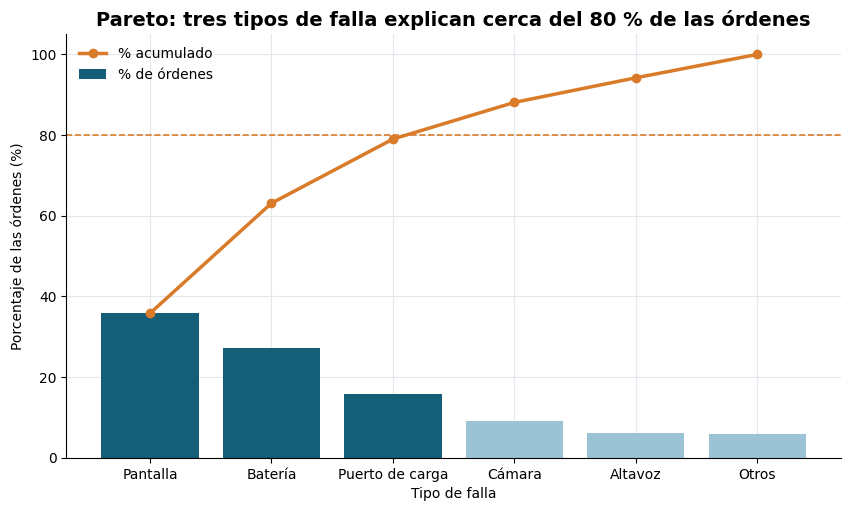

In [14]:
pareto = (datos["tipo_falla"].value_counts(normalize=True) * 100).round(1).to_frame("% de órdenes")
pareto["% acumulado"] = pareto["% de órdenes"].cumsum()
display(pareto)

fig, ax = plt.subplots()
colores = [OSCURO if a <= 80 else "#9CC3D5" for a in pareto["% acumulado"]]   # oscuro: lo que suma hasta el 80 %
ax.bar(pareto.index, pareto["% de órdenes"], color=colores, label="% de órdenes")
ax.plot(pareto.index, pareto["% acumulado"], color=NARANJA, marker="o", lw=2.5, label="% acumulado")
ax.axhline(80, color=NARANJA, ls="--", lw=1.2)
ax.set(title="Pareto: tres tipos de falla explican cerca del 80 % de las órdenes",
       xlabel="Tipo de falla", ylabel="Porcentaje de las órdenes (%)", ylim=(0, 105))
ax.legend(frameon=False); plt.show()

### 5.2 ¿El stock se relaciona con los días de reparación? (dispersión y correlación de Pearson)

Dos variables numéricas, una por repuesto: el stock promedio y el promedio de días de reparación.

r de Pearson = -0.84 (valor p = 0.0000)
Recta de regresión: días = 7.5 -0.27 × stock


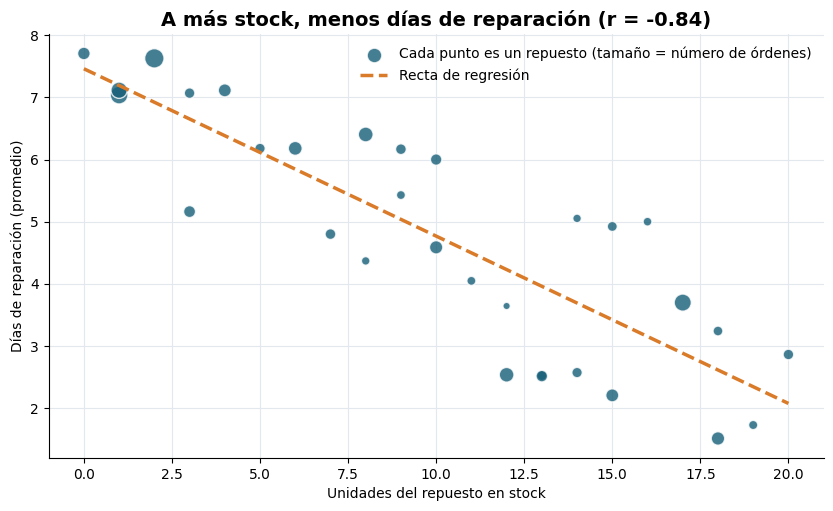

In [15]:
por_repuesto = (datos.groupby("repuesto_ref")
                     .agg(dias=("dias_reparacion", "mean"), stock=("stock_promedio", "first"), ordenes=("orden_id", "count"))
                     .reset_index())
r, valor_p = stats.pearsonr(por_repuesto["stock"], por_repuesto["dias"])
pendiente, intercepto = np.polyfit(por_repuesto["stock"], por_repuesto["dias"], 1)
print(f"r de Pearson = {r:.2f} (valor p = {valor_p:.4f})")
print(f"Recta de regresión: días = {intercepto:.1f} {pendiente:+.2f} × stock")

fig, ax = plt.subplots()
ax.scatter(por_repuesto["stock"], por_repuesto["dias"], s=por_repuesto["ordenes"] * 2, color=OSCURO, alpha=.8,
           edgecolor="white", label="Cada punto es un repuesto (tamaño = número de órdenes)")
x = np.linspace(0, por_repuesto["stock"].max(), 50)
ax.plot(x, intercepto + pendiente * x, color=NARANJA, ls="--", lw=2.5, label="Recta de regresión")
ax.set(title=f"A más stock, menos días de reparación (r = {r:.2f})",
       xlabel="Unidades del repuesto en stock", ylabel="Días de reparación (promedio)")
ax.legend(frameon=False); plt.show()

**Cuidado:** una correlación fuerte no prueba causalidad. Aun así, la nota «sin stock» de los técnicos apoya la explicación: cuando el repuesto no está en bodega, hay que pedirlo al proveedor.

In [16]:
datos.groupby("sin_stock")["dias_reparacion"].agg(["count", "median", "mean"]).round(1)

,count,median,mean
sin_stock,,,
No,912,4.0,4.4
Sí,288,7.0,7.1


### 5.3 ¿Hay diferencias entre sedes? (diagrama de caja y ANOVA)

Una variable numérica (días) y una categórica con tres grupos (sede).

ANOVA: F = 61.3, valor p = 0.0000
sede
Centro    4.0
Norte     6.0
Sur       4.0
Name: dias_reparacion, dtype: float64


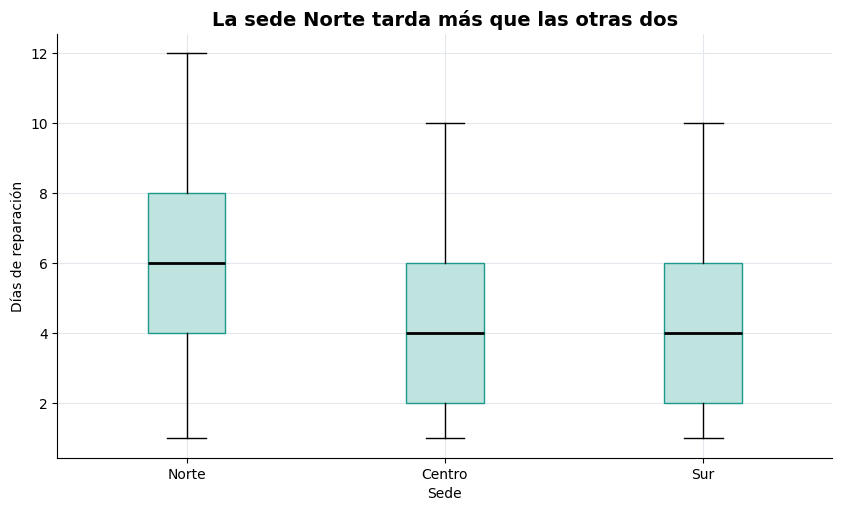

In [17]:
sedes = ["Norte", "Centro", "Sur"]
grupos = [datos.loc[datos["sede"] == s, "dias_reparacion"] for s in sedes]
F, p_anova = stats.f_oneway(*grupos)
print(f"ANOVA: F = {F:.1f}, valor p = {p_anova:.4f}")
print(datos.groupby("sede")["dias_reparacion"].median())

fig, ax = plt.subplots()
ax.boxplot(grupos, tick_labels=sedes, patch_artist=True,
           boxprops=dict(facecolor="#BFE3DE", edgecolor=TEAL), medianprops=dict(color="black", lw=2))
ax.set(title="La sede Norte tarda más que las otras dos", xlabel="Sede", ylabel="Días de reparación"); plt.show()

### 5.4 ¿A qué repuestos se asocian las quejas por demora? (integrar texto y números)

Aquí se ve el valor de unir las reseñas con las órdenes por el número de orden.

In [18]:
quejas = datos[datos["menciona_demora"] == "Sí"]
top = quejas["repuesto_ref"].value_counts()
top_pantallas = top[top.index.str.startswith("PAN")].head(5)
print(f"Reseñas que mencionan demora: {len(quejas)}")
print(f"Las 5 referencias de pantalla con más quejas reúnen el {top_pantallas.sum() / len(quejas):.0%} de las quejas por demora")
top_pantallas.to_frame("quejas").join(inventario.set_index("repuesto_ref")[["descripcion", "stock_promedio"]])

Reseñas que mencionan demora: 60
Las 5 referencias de pantalla con más quejas reúnen el 72% de las quejas por demora


,quejas,descripcion,stock_promedio
repuesto_ref,,,
PAN-02,15,Pantalla AMOLED Galaxy A34,2
PAN-01,11,Pantalla AMOLED Galaxy A54,1
PAN-05,10,Pantalla LCD Motorola G54,1
PAN-03,5,Pantalla LCD Redmi Note 12,0
PAN-09,2,Pantalla LCD Motorola E13,9


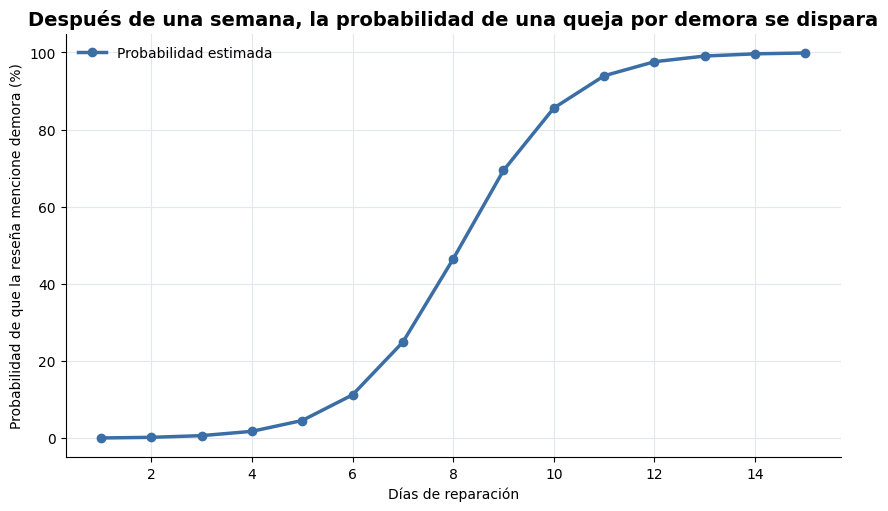

Con 3 días: 1%
Con 7 días: 25%
Con 10 días: 86%


In [19]:
# ¿Qué tan probable es una queja por demora según los días de espera? (regresión logística)
con_resena = datos.dropna(subset=["menciona_demora"])
modelo = LogisticRegression().fit(con_resena[["dias_reparacion"]], (con_resena["menciona_demora"] == "Sí"))
dias = np.arange(1, 16).reshape(-1, 1)
prob = modelo.predict_proba(pd.DataFrame(dias, columns=["dias_reparacion"]))[:, 1]

fig, ax = plt.subplots()
ax.plot(dias, prob * 100, color=AZUL, lw=2.5, marker="o", label="Probabilidad estimada")
ax.set(title="Después de una semana, la probabilidad de una queja por demora se dispara",
       xlabel="Días de reparación", ylabel="Probabilidad de que la reseña mencione demora (%)")
ax.legend(frameon=False); plt.show()
for d in (3, 7, 10):
    print(f"Con {d} días: {prob[d-1]:.0%}")

## Conclusión y recomendación

Completa con tus resultados (las cifras aparecen en las salidas de las celdas anteriores):

1. **Priorizar** los tres tipos de falla que explican cerca del 80 % de las órdenes: pantalla, batería y puerto de carga.
2. **Subir el stock** de las cinco referencias de pantalla que concentran la mayoría de las quejas por demora; son las de menor stock.
3. **Revisar el proceso de la sede Norte**, que tarda más que las demás.
4. **Prometer tiempos realistas:** después de una semana de espera, las quejas por demora se vuelven mucho más probables.

**Preguntas de reflexión**

- ¿Qué información te dieron las reseñas que no estaba en la tabla de órdenes?
- El diccionario coincidió casi siempre con la etiqueta humana porque las reseñas son cortas y sencillas. ¿Qué pasaría con reseñas reales, con ironía o errores de ortografía? ¿Cómo lo mejorarías?
- Si tuvieras que presentar solo un gráfico a la gerencia, ¿cuál elegirías y por qué?

---
**Referencias principales:** Dominguez-Péry et al. (2023); Illowsky y Dean (2013); Jamal et al. (2023); Jehnen et al. (2026); Sarker et al. (2022); Stočes et al. (2026). Las referencias completas están en el ODC.

**Licencia:** CC BY 4.0 · Autor: Hansel Andres Parra Enciso · Universidad de Cundinamarca.